In [ ]:
import pandas as pd
#Pandas have 2 datastructres - Dataframe and Series

df = pd.read_csv(r"C:\Users\gokul\OneDrive\Desktop\MCA\SEM 2\Python\Classworks\president_heights1.csv")
df.head()

,order,name,height(cm)
0,16,Abraham Lincoln,193.0
1,7,Andrew Jackson,185.0
2,17,Andrew Johnson,178.0
3,44,Barack Obama,NaN
4,23,Benjamin Harrison,168.0


In [ ]:
df.info()
#how to identify if there are null values?
#The first two values have 42 entries but the height column has only 37 entries

<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   order       42 non-null     int64  
 1   name        42 non-null     str    
 2   height(cm)  37 non-null     float64
dtypes: float64(1), int64(1), str(1)
memory usage: 1.7 KB


In [ ]:
df.describe()
#python will not consider non numberic values for summary statistics
#how many values are present it will give count for those values

,order,height(cm)
count,42.000000,37.000000
mean,22.476190,179.378378
std,13.152461,7.361127
min,1.000000,163.000000
25%,11.250000,173.000000
50%,22.000000,180.000000
75%,33.750000,183.000000
max,44.000000,193.000000


In [12]:
print(df.loc[0])
#Single row slection by label

order                      16
name          Abraham Lincoln
height(cm)              193.0
Name: 0, dtype: object


In [14]:
print(df.iloc[0:5])
#First five rows

   order               name  height(cm)
0     16    Abraham Lincoln       193.0
1      7     Andrew Jackson       185.0
2     17     Andrew Johnson       178.0
3     44       Barack Obama         NaN
4     23  Benjamin Harrison       168.0


In [13]:
print(df.iloc[0:5, 0:2])
#First 5 rows(0-4) and first two 2 columns(index 0 and 1)

   order               name
0     16    Abraham Lincoln
1      7     Andrew Jackson
2     17     Andrew Johnson
3     44       Barack Obama
4     23  Benjamin Harrison


In [ ]:
print(df.iloc[[0, 2, 9]])
#Specific non consecutive rows

   order                   name  height(cm)
0     16        Abraham Lincoln       193.0
2     17         Andrew Johnson       178.0
9     32  Franklin D. Roosevelt       188.0


In [ ]:
print(df.iloc[[0, 2, 4], [1, 2]])
#Specific non consecutive rows and columns

                name  height(cm)
0    Abraham Lincoln       193.0
2     Andrew Johnson       178.0
4  Benjamin Harrison       168.0


In [17]:
#Display every second row upto 20 rows
print(df.iloc[0:20:2])

    order                  name  height(cm)
0      16       Abraham Lincoln       193.0
2      17        Andrew Johnson       178.0
4      23     Benjamin Harrison       168.0
6      30       Calvin Coolidge       178.0
8      34  Dwight D. Eisenhower       179.0
10     14       Franklin Pierce         NaN
12     43        George W. Bush       182.0
14     38           Gerald Ford         NaN
16     31        Herbert Hoover       182.0
18     15        James Buchanan       183.0


In [ ]:
df1 = df.dropna()

df1['era'] = pd.cut(df1['order'], bins = [0, 15, 30, 45], labels = ['Early Era', 'Middle Era', 'Modern Era'])

In [ ]:
df[df['height(cm)'].isnull()]
#select rows with missing height data

,order,name,height(cm)
3,44,Barack Obama,NaN
10,14,Franklin Pierce,NaN
14,38,Gerald Ford,NaN
17,20,James A. Garfield,NaN
24,35,John F. Kennedy,NaN


In [20]:
df[df['height(cm)'].notnull()]
#select rows with valid (non-null) height data

,order,name,height(cm)
0,16,Abraham Lincoln,193.0
1,7,Andrew Jackson,185.0
2,17,Andrew Johnson,178.0
4,23,Benjamin Harrison,168.0
5,42,Bill Clinton,188.0
6,30,Calvin Coolidge,178.0
7,21,Chester A. Arthur,183.0
8,34,Dwight D. Eisenhower,179.0
9,32,Franklin D. Roosevelt,188.0
11,41,George H. W. Bush,188.0


In [21]:
#Drop any rows containing missing data
clean_df = df.dropna()
print(df.shape)
print(clean_df.shape)

(42, 3)
(37, 3)


In [ ]:
#Forward fill - In place of null values the previous values will be filled
Ffill = df.ffill()
print(Ffill)

    order                    name  height(cm)
0      16         Abraham Lincoln       193.0
1       7          Andrew Jackson       185.0
2      17          Andrew Johnson       178.0
3      44            Barack Obama       178.0
4      23       Benjamin Harrison       168.0
5      42            Bill Clinton       188.0
6      30         Calvin Coolidge       178.0
7      21       Chester A. Arthur       183.0
8      34    Dwight D. Eisenhower       179.0
9      32   Franklin D. Roosevelt       188.0
10     14         Franklin Pierce       188.0
11     41       George H. W. Bush       188.0
12     43          George W. Bush       182.0
13      1       George Washington       189.0
14     38             Gerald Ford       189.0
15     33         Harry S. Truman       175.0
16     31          Herbert Hoover       182.0
17     20       James A. Garfield       182.0
18     15          James Buchanan       183.0
19     11           James K. Polk       173.0
20      4           James Madison 

In [ ]:
#Backward fill - In place of null values the previous values will be filled from backward
Bfill = df.bfill()
print(Bfill)

    order                    name  height(cm)
0      16         Abraham Lincoln       193.0
1       7          Andrew Jackson       185.0
2      17          Andrew Johnson       178.0
3      44            Barack Obama       168.0
4      23       Benjamin Harrison       168.0
5      42            Bill Clinton       188.0
6      30         Calvin Coolidge       178.0
7      21       Chester A. Arthur       183.0
8      34    Dwight D. Eisenhower       179.0
9      32   Franklin D. Roosevelt       188.0
10     14         Franklin Pierce       188.0
11     41       George H. W. Bush       188.0
12     43          George W. Bush       182.0
13      1       George Washington       189.0
14     38             Gerald Ford       175.0
15     33         Harry S. Truman       175.0
16     31          Herbert Hoover       182.0
17     20       James A. Garfield       183.0
18     15          James Buchanan       183.0
19     11           James K. Polk       173.0
20      4           James Madison 

In [28]:
early_tall = df[(df['height(cm)'] > 185) & (df['order'] <= 20)]
print(early_tall)

extremes = df[(df['height(cm)'] > 190) | (df['height(cm)'] > 165)]
print(extremes)

not_lincoln = df[~(df['name'] == 'Abraham Lincoln')]
print(not_lincoln)

    order               name  height(cm)
0      16    Abraham Lincoln       193.0
13      1  George Washington       189.0
34      3   Thomas Jefferson       189.0
    order                    name  height(cm)
0      16         Abraham Lincoln       193.0
1       7          Andrew Jackson       185.0
2      17          Andrew Johnson       178.0
4      23       Benjamin Harrison       168.0
5      42            Bill Clinton       188.0
6      30         Calvin Coolidge       178.0
7      21       Chester A. Arthur       183.0
8      34    Dwight D. Eisenhower       179.0
9      32   Franklin D. Roosevelt       188.0
11     41       George H. W. Bush       188.0
12     43          George W. Bush       182.0
13      1       George Washington       189.0
15     33         Harry S. Truman       175.0
16     31          Herbert Hoover       182.0
18     15          James Buchanan       183.0
19     11           James K. Polk       173.0
21      5            James Monroe       183.0
22     3

In [32]:
df[(df['height(cm)'] == df['height(cm)'].max())]

,order,name,height(cm)
0,16,Abraham Lincoln,193.0
27,36,Lyndon B. Johnson,193.0


In [34]:
top_5 = df.head(5)
print(top_5)

bottom_5 = df.tail(5)
print(bottom_5)

tallest_3 = df.nlargest(3, 'height(cm)')
print(tallest_3)

shortest_3 = df.nsmallest(3, 'height(cm)')
print(shortest_3)

   order               name  height(cm)
0     16    Abraham Lincoln       193.0
1      7     Andrew Jackson       185.0
2     17     Andrew Johnson       178.0
3     44       Barack Obama         NaN
4     23  Benjamin Harrison       168.0
    order                    name  height(cm)
37      9  William Henry Harrison       173.0
38     27     William Howard Taft       182.0
39     25        William McKinley       170.0
40     28          Woodrow Wilson       180.0
41     12          Zachary Taylor       173.0
    order               name  height(cm)
0      16    Abraham Lincoln       193.0
27     36  Lyndon B. Johnson       193.0
13      1  George Washington       189.0
    order               name  height(cm)
20      4      James Madison       163.0
4      23  Benjamin Harrison       168.0
28      8   Martin Van Buren       168.0


In [35]:
random_5 = df.sample(n = 5, random_state = 43)
print(random_5)

random_pct = df.sample(frac = 0.2, random_state = 41)
print(random_pct)

    order              name  height(cm)
14     38       Gerald Ford         NaN
6      30   Calvin Coolidge       178.0
5      42      Bill Clinton       188.0
39     25  William McKinley       170.0
26     10        John Tyler       183.0
    order                  name  height(cm)
30     37         Richard Nixon       182.0
41     12        Zachary Taylor       173.0
8      34  Dwight D. Eisenhower       179.0
33     26    Theodore Roosevelt       178.0
40     28        Woodrow Wilson       180.0
7      21     Chester A. Arthur       183.0
5      42          Bill Clinton       188.0
38     27   William Howard Taft       182.0


<Axes: title={'center': 'Top 5 Tallest Presidents'}, xlabel='order'>

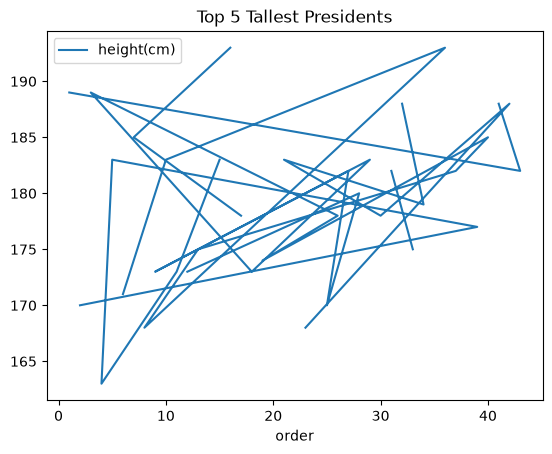

In [37]:
df.plot(x = 'order', y = 'height(cm)', title = 'Top 5 Tallest Presidents')

<Axes: title={'center': 'Top 5 Tallest Presidents'}, xlabel='name'>

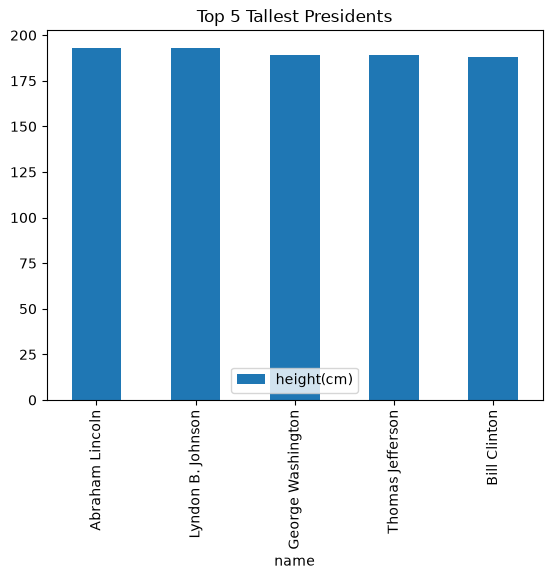

In [36]:
top5 = df.nlargest(5, 'height(cm)')
top5.plot.bar(x = 'name', y = 'height(cm)', title = 'Top 5 Tallest Presidents')